---
# PLS Feature Selection and Analysis Tool
---

**PURPOSE:**
This script performs Partial Least Squares (PLS) regression analysis to:
1. Identify the most important input features for predicting an output variable
2. Visualize feature contributions and PLS component loadings
3. Export results and plots for further analysis

**REQUIREMENTS:**
- Python 3.12+
- Libraries: numpy, pandas, matplotlib, scikit-learn, openpyxl
- See instructions in README/SETUP.md files on how to install libraries

**USAGE:**
1. Run the script: python **pls_analysis.ipnyb**
2. Follow the interactive prompts to:
   - Specify your Excel file location
   - Select input and output columns
   - Set analysis parameters
   - Choose where to save results


---

PLS FEATURE SELECTION AND ANALYSIS TOOL

This tool will help you:
  1. Identify the most important features for predicting your output
  2. Visualize PLS component loadings and feature contributions
  3. Check selection stability by repeating the full pipeline inside CV folds
  4. Generate publication-quality plots and an Excel report

Let's get started!


STEP 1: LOAD YOUR DATA
Instructions:
  • Enter only the directory path (NOT the file name)
  • The program will automatically detect supported files (.csv, .xls, .xlsx)
  • You will select the file using a number



Enter the directory path (e.g., ./ or ~/ or full path):  C:/



────────────────────────────────────────────────────────────────────────────────
Available data files:
────────────────────────────────────────────────────────────────────────────────
  1. MP_cleaned_dataset.csv  (31 columns detected)
────────────────────────────────────────────────────────────────────────────────



Enter the file number:  1



✓ Successfully loaded 'MP_cleaned_dataset.csv'
Rows: 6432 | Columns: 31

Now select your input and output variables...

────────────────────────────────────────────────────────────────────────────────
Available columns (copy-paste from here):
────────────────────────────────────────────────────────────────────────────────
material_id, formula, crystal_system, species, spacegroup, is_stable, IS_METAL, is_magnetic, ordering, NE, NA, BGAP, EPA, FEPA, EFMR, TM, MSITE, V, VPA, D, BM, SM, YM, PR, PUGR, IPUGR, vs, vl, vm, DT, debye_temperature_source
────────────────────────────────────────────────────────────────────────────────


...


 Results will be saved in: C:/PLS_Results



Enter prefix for saved files (e.g., 'predictions_1'):  Debye_temperature_MP



STEP 4: RUNNING PLS ANALYSIS

OPTIMIZING PLS PARAMETERS
This may take a few minutes depending on your dataset size...


C:\Users\SVI\plsr_venv2\Lib\site-packages\numpy\ma\core.py:2885: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,



 ✓ Optimization complete!

 Best PLS Parameters Found:
  • max_iter: 500
  • tol: 1e-08
  • Cross-validated R²   : 0.8241
  • Cross-validated RMSE : 77.6764 (original units)

CV RMSE (original units): 77.6764 | In-sample RMSE (original units): 69.0199

Analyzing 5 PLS components...

STEP 5: SELECTING IMPORTANT FEATURES

 ✓ Selected 14 important features:
  1. SM
  2. YM
  3. BM
  4. VPA
  5. PR
  6. PUGR
  7. IPUGR
  8. D
  9. BGAP
  10. EFMR
  11. NA
  12. V
  13. FEPA
  14. EPA

Calculating explained variance for selected features...

STEP 6B: FOLD-WISE SELECTION STABILITY CHECK
Repeating the FULL selection pipeline inside each training fold (5-fold x 10 repeats = 50 runs).
In every run, scaling, PLS fitting, component screening, loading screening and nested linear regression use the training fold only.
 ✓ Reference (full-data) run reproduces the STEP 5 feature order.
Full-data NLR-retained features (relative gain ≥ 0.05, ΔR² ≥ 0.001): SM, YM, VPA, D

NLR relative-gain table (full d

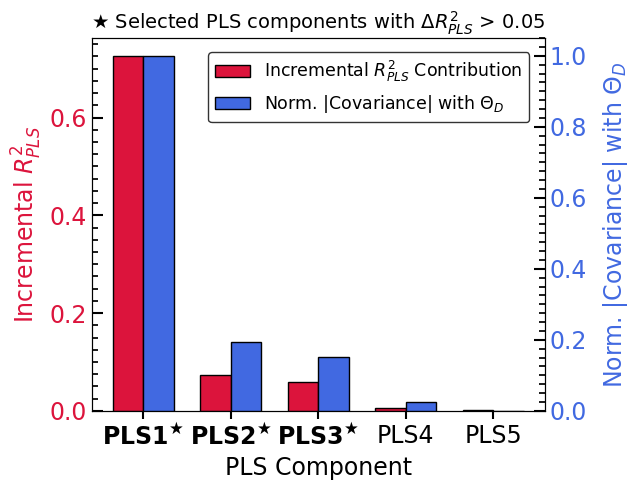

  ✓ Saved: C:/PLS_Results\Debye_temperature_MP_1_pls_component_analysis.pdf
Creating plot 2: PLS Loading Heatmap (selected components only)...


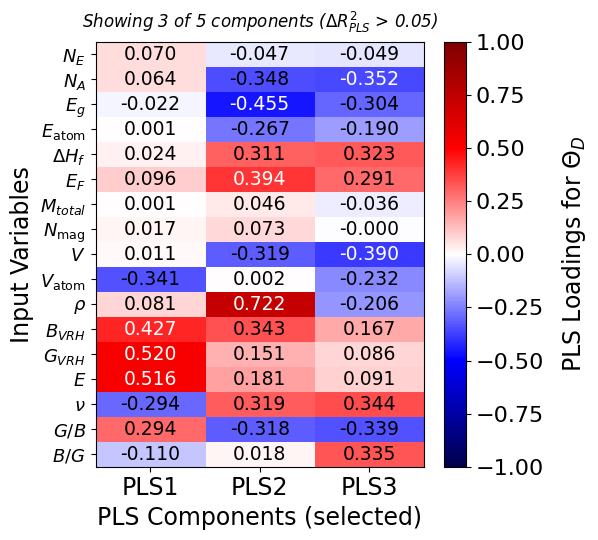

  ✓ Saved: C:/PLS_Results\Debye_temperature_MP_2_loading_heatmap.pdf
Creating plot 3: Feature Contribution Analysis...


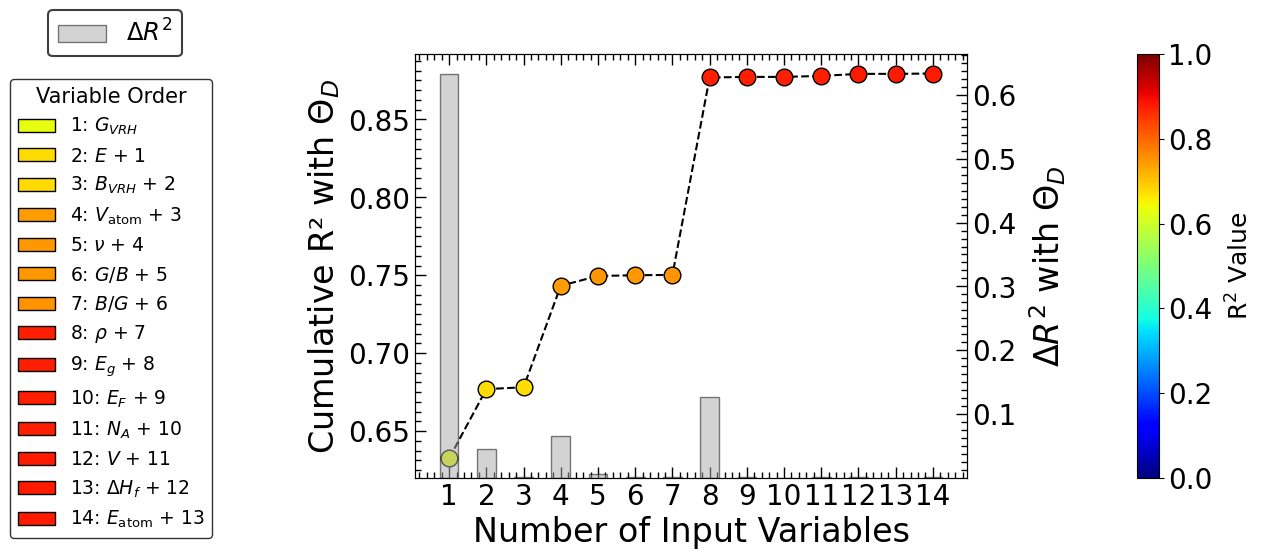

  ✓ Saved: C:/PLS_Results\Debye_temperature_MP_3_feature_contributions.pdf
Creating plot 4: NLR Relative Gain...


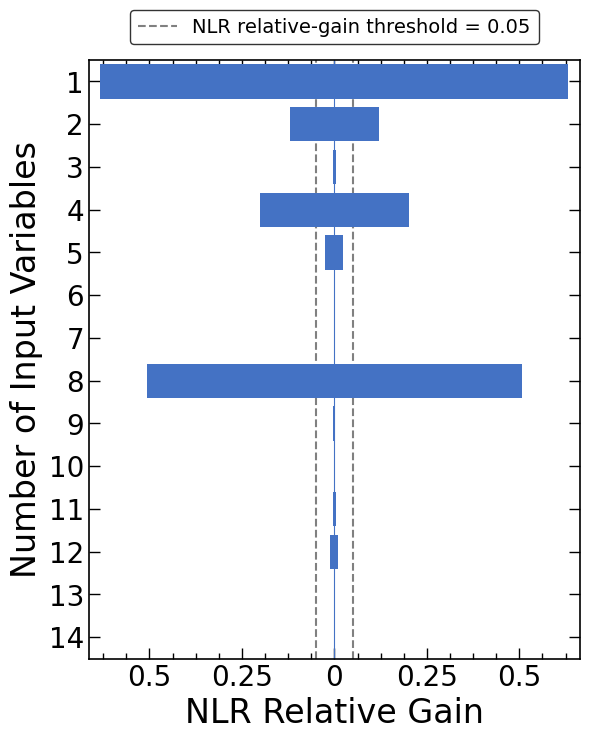

  ✓ Saved: C:/PLS_Results\Debye_temperature_MP_4_nlr_relative_gain.pdf
Creating plot 5: Fold-wise Selection Frequency...


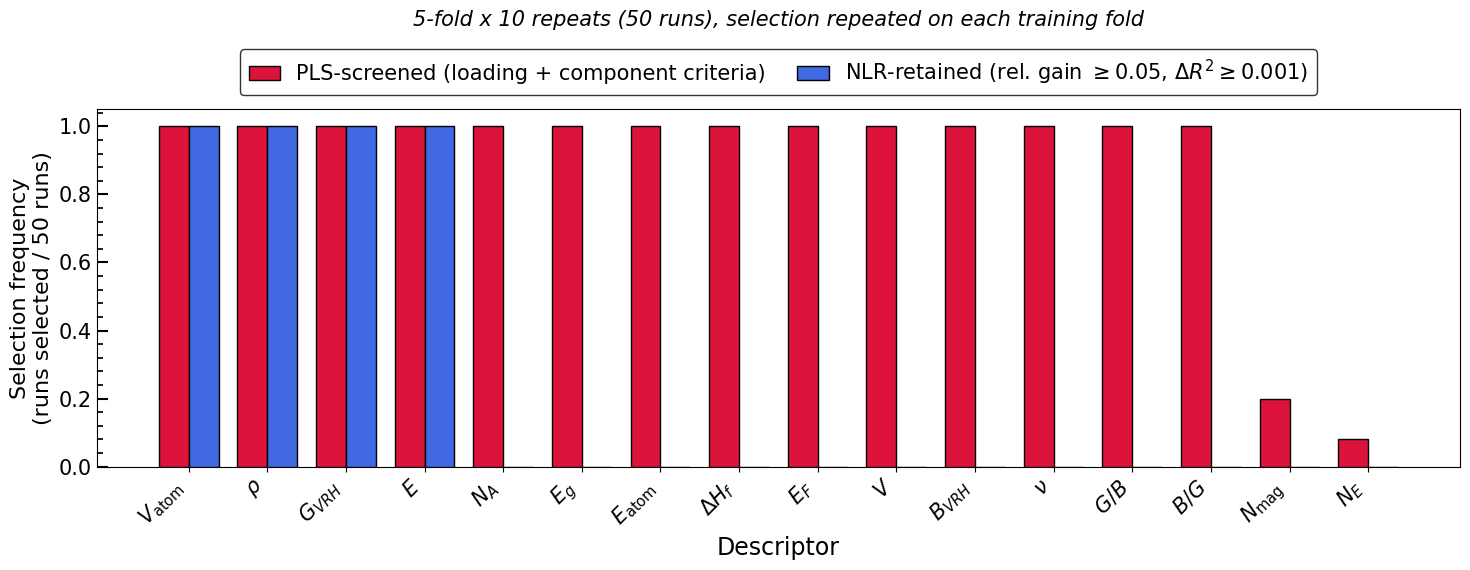

  ✓ Saved: C:/PLS_Results\Debye_temperature_MP_5_foldwise_selection_frequency.pdf

STEP 8: EXPORTING RESULTS TO EXCEL
 ✓ Excel workbook saved: C:/PLS_Results\Debye_temperature_MP_results.xlsx
   Sheets: Metadata and Grid search | PLS Component Summary | PLS Loadings (All) | PLS Loadings (Selected) | NLR Feature Selection | Foldwise Selection Freq | Foldwise Runs | Foldwise Summary

ANALYSIS COMPLETE!

Summary:
  • Number of PLS components: 5 (user-defined)
  • CV R² / CV RMSE (orig. units): 0.8241 / 77.6764
  • Valid components (incremental R2 > 0.05): ['PLS1', 'PLS2', 'PLS3']
  • Number of selected features: 14
  • Final R² (all features): 0.8794
  • Full-data NLR-retained set: SM, YM, VPA, D
  • Fold-wise runs retaining exactly that set: 50/50 (100.0%)

Results saved to:
  C:/PLS_Results

Files generated:
  • Debye_temperature_MP_1_pls_component_analysis.pdf
  • Debye_temperature_MP_2_loading_heatmap.pdf  (selected components only)
  • Debye_temperature_MP_3_feature_contributions.pdf

In [2]:
#############################################################################################
# Importing required libraries
#############################################################################################

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator

import os
import sys

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, RepeatedKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, make_scorer

#############################################################################################
# Color codes and functions for terminal output
#############################################################################################

RED = "\033[91m"
GREEN = "\033[92m"
YELLOW = "\033[93m"
BLUE = "\033[94m"
RESET = "\033[0m"

def print_error(message):
    """Print error messages in red."""
    print(f"{RED}Error: {message}{RESET}")

def print_success(message):
    """Print success messages in green."""
    print(f"{GREEN}{message}{RESET}")

def print_info(message):
    """Print informational messages in blue."""
    print(f"{BLUE}{message}{RESET}")

def print_section(title):
    """Print a section header."""
    print(f"\n{'='*80}")
    print(f"{YELLOW}{title}{RESET}")
    print('='*80)


#############################################################################################
# Font for graphical plots
#############################################################################################

plt.rcParams['font.family'] = 'sans-serif'

YES_VALUES = ["yes", "y", "Yes", "Y", "YES"]

#############################################################################################
# Function for loading data and defining input and target variables
# Supports both Excel (.xls, .xlsx) and CSV (.csv) file formats
#############################################################################################

def load_data():
    """
    Interactive function to load Excel or CSV data and select columns.
    
    Returns:
        tuple: (dataframe, input_columns, output_column, output_latex_name)
    """
    print_section("STEP 1: LOAD YOUR DATA")
    print_info("Instructions:")
    print("  • Enter only the directory path (NOT the file name)")
    print("  • The program will automatically detect supported files (.csv, .xls, .xlsx)")
    print("  • You will select the file using a number\n")
    
    while True:
        folder_path = input("Enter the directory path (e.g., ./ or ~/ or full path): ").strip()
        folder_path = os.path.expanduser(folder_path)
        
        if not os.path.isdir(folder_path):
            print_error(f"Invalid directory: {folder_path}")
            choice = input("Do you want to try again? (yes/no): ").strip().lower()
            if choice not in ["yes", "y", "Yes", "Y", "YES"]:
                print("Exiting the program.")
                return None, None, None, None
            continue
        
        # Automatically detect supported files
        supported_ext = (".csv", ".xls", ".xlsx")
        files = [f for f in os.listdir(folder_path) if f.endswith(supported_ext)]
        files = sorted(files)
        
        if not files:
            print_error("No supported files (.csv, .xls, .xlsx) found in this directory.")
            choice = input("Do you want to try another directory? (yes/no): ").strip().lower()
            if choice not in ["yes", "y", "Yes", "Y", "YES"]:
                print("Exiting the program.")
                return None, None, None, None
            continue
        
        print("\n" + "─"*80)
        print("Available data files:")
        print("─"*80)
        for i, f in enumerate(files, 1):
            try:
                full_path_temp = os.path.join(folder_path, f)
                if f.endswith((".xls", ".xlsx")):
                    temp_df = pd.read_excel(full_path_temp, nrows=5)
                else:
                    temp_df = pd.read_csv(full_path_temp, nrows=5)
                print(f"{i:3d}. {f}  ({len(temp_df.columns)} columns detected)")
            except:
                print(f"{i:3d}. {f}")
        print("─"*80)
        
        # File selection loop
        while True:
            try:
                choice = int(input("\nEnter the file number: "))
                if choice < 1 or choice > len(files):
                    raise ValueError
                break
            except ValueError:
                print_error("Invalid selection. Please enter a valid number.")
        
        file_name = files[choice - 1]
        full_path = os.path.join(folder_path, file_name)
        
        # Determine file format and read accordingly
        if file_name.endswith((".xls", ".xlsx")):
            read_func = pd.read_excel
        else:
            read_func = pd.read_csv
        
        try:
            df = read_func(full_path)
            print_success(f"\n✓ Successfully loaded '{file_name}'")
            print_success(f"Rows: {len(df)} | Columns: {len(df.columns)}")
            
            print_info("\nNow select your input and output variables...")

            # Print all column names horizontally for easy copy-paste
            all_cols_str = ", ".join(df.columns.tolist())
            print("\n" + "─"*80)
            print("Available columns (copy-paste from here):")
            print("─"*80)
            print(all_cols_str)
            print("─"*80)

            # Input columns (name-based copy-paste selection)
            while True:
                try:
                    raw_input = input("\nPaste INPUT column names (comma-separated): ").strip()
                    input_cols = [c.strip() for c in raw_input.split(',')]
                    invalid = [c for c in input_cols if c not in df.columns]
                    if invalid:
                        print_error(f"Column(s) not found: {', '.join(invalid)}. Please check spelling.")
                        continue
                    break
                except:
                    print_error("Invalid input. Please paste valid column names.")

            # Output column (name-based copy-paste selection)
            while True:
                try:
                    raw_output = input("\nPaste OUTPUT column name (single column): ").strip()
                    if ',' in raw_output:
                        print_error("Only one output column is allowed. Please paste a single column name.")
                        continue
                    if raw_output not in df.columns:
                        print_error(f"Column '{raw_output}' not found. Please check spelling.")
                        continue
                    output_col = raw_output
                    break
                except:
                    print_error("Invalid input. Please paste a valid column name.")
            
            print("\n" + "─"*80)
            print_success("SELECTION SUMMARY")
            print("─"*80)
            print(f"Input Columns ({len(input_cols)}): {', '.join(input_cols)}")
            print(f"Output Column: {output_col}")
            print("─"*80)
            
            print("\nPreview of selected data (first 5 rows):")
            print(df[input_cols + [output_col]].head().to_string())
            
            confirm = input("\nDoes this look correct? (yes/no): ").strip().lower()
            if confirm in ["yes", "y", "Yes", "Y", "YES"]:
                return df, input_cols, output_col, folder_path
            else:
                print("Let's try again...\n")
                continue
                
        except Exception as e:
            print_error(f"An error occurred: {str(e)}")
            return None, None, None, None

#############################################################################################
# Function to load symbol conversion (optional)
#############################################################################################

def load_symbol_map(base_path):
    """
    Load symbol conversion from symbol_conversion.txt if available.

    File format (each line):
    COLUMN_NAME = $LaTeX_symbol$

    Example:
    NE = $N_E$
    BGAP = $E_g$

    Returns:
        dict: mapping of column names to LaTeX symbols
    """
    print_section("STEP 1B: SYMBOL CONFIGURATION")

    use_file = input("Do you want to use symbol_conversion.txt? (yes/no): ").strip().lower()

    if use_file not in ["yes", "y", "Yes", "Y", "YES"]:
        print_info("Using column names directly (no symbol conversion).")
        return {}

    same_location = input("Is symbol_conversion.txt in the SAME folder as your data file? (yes/no): ").strip().lower()

    if same_location in ["yes", "y", "Yes", "Y", "YES"]:
        symbol_path = os.path.join(base_path, "symbol_conversion.txt")
    else:
        symbol_path = input("Enter full path to symbol_conversion.txt: ").strip()
        symbol_path = os.path.expanduser(symbol_path)

    if not os.path.exists(symbol_path):
        print_error(f"symbol_conversion.txt not found at: {symbol_path}")
        print_info("Proceeding WITHOUT symbol conversion.")
        return {}

    symbol_map = {}
    try:
        with open(symbol_path, "r") as f:
            for line in f:
                line = line.strip()
                if not line or "=" not in line:
                    continue
                key, val = line.split("=", 1)
                symbol_map[key.strip()] = val.strip()

        print_success(f"✓ Loaded {len(symbol_map)} symbol mappings")
        return symbol_map

    except Exception as e:
        print_error(f"Error reading symbol file: {str(e)}")
        print_info("Proceeding WITHOUT symbol conversion.")
        return {}

#############################################################################################
# Function for getting float inputs for thresholds
#############################################################################################
def get_float_input(prompt, default=None, min_val=None, max_val=None):
    """
    Get validated float input from the user.
    
    Args:
        prompt: Question to ask user
        default: Default value if user presses Enter
        min_val: Minimum allowed value
        max_val: Maximum allowed value
    
    Returns:
        float: Validated numeric input
    """
    while True:
        try:
            if default is not None:
                value = input(f"{prompt} [default={default}]: ")
            else:
                value = input(f"{prompt}: ")
            
            if not value.strip() and default is not None:
                return default
            
            value = float(value)
            
            if min_val is not None and value < min_val:
                print_error(f"Value must be at least {min_val}")
                continue
            if max_val is not None and value > max_val:
                print_error(f"Value must be at most {max_val}")
                continue
            
            return value
        except ValueError:
            print_error("Please enter a valid numeric value")

#############################################################################################
# Function for defining path for saving plots and CSV results
#############################################################################################

def get_save_path():
    """
    Get and validate the directory where results should be saved.
    
    Returns:
        str: Path to results directory
    """
    print_section("STEP 3: SET UP RESULTS DIRECTORY")
    
    while True:
        save_path = input("Enter directory path to save results: ").strip()
        save_path = os.path.expanduser(save_path)
        
        if not os.path.exists(save_path):
            print_error(f"Path not found: {save_path}")
            choice = input("Do you want to try again? (yes/no): ").strip().lower()
            if choice not in ["yes", "y", "Yes", "Y", "YES"]:
                print("Exiting save setup.")
                return None
            continue
        
        results_dir = os.path.join(save_path, "PLS_Results")
        os.makedirs(results_dir, exist_ok=True)
        print_success(f"\n Results will be saved in: {results_dir}")
        return results_dir

#############################################################################################
# Function to estimate Root mean squared error
#############################################################################################

def rmse_score(y_true, y_pred):
    """Return negative RMSE (for minimization in GridSearchCV)."""
    return -np.sqrt(mean_squared_error(y_true, y_pred))

#############################################################################################
# Function for PLS regression (hyperparameter optimisation)
#############################################################################################
def optimize_pls_parameters(X_raw, y_raw, n_comp, tune_components=False):
    """
    Perform grid search cross-validation to find optimal PLS parameters.

    NOTE (leakage fix): the grid search is run on the UNSCALED data. PLSRegression
    (scale=True) standardises X and y internally using the training part of each
    fold only, so no information from the validation fold enters the scaling. The
    CV RMSE is therefore directly in the original units of the target (e.g. K).

    Args:
        X_raw:           Unscaled input features, shape (n, p)
        y_raw:           Unscaled output variable, shape (n, 1)
        n_comp:          Number of PLS components (used as the maximum if tune_components)
        tune_components: If True, n_components is tuned by CV over 2..n_comp

    Returns:
        (best_estimator, best_r2, best_rmse, grid_search)
    """
    print_section("OPTIMIZING PLS PARAMETERS")
    print_info("This may take a few minutes depending on your dataset size...")
    
    param_grid = {
        "max_iter": [500, 800, 1000, 2000],
        "tol": [1e-8, 1e-6, 1e-4]
    }
    if tune_components:
        param_grid["n_components"] = list(range(2, n_comp + 1))
        print_info(f"Tuning number of components over 2..{n_comp} by cross-validation.")
    
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    pls_base = PLSRegression(n_components=n_comp, scale=True)
    scoring = {
        "R2": make_scorer(r2_score),
        "RMSE": make_scorer(rmse_score)
    }
    
    grid_search = GridSearchCV(
        estimator=pls_base,
        param_grid=param_grid,
        scoring=scoring,
        refit="RMSE",  # model will refit using the best RMSE
        cv=cv,
        n_jobs=1,
        verbose=0,
        return_train_score=True
    )
    
    grid_search.fit(X_raw, y_raw)

    best_rmse = -grid_search.best_score_   # original units
    best_r2 = grid_search.cv_results_['mean_test_R2'][grid_search.best_index_]
    
    print_success("\n ✓ Optimization complete!")
    
    print("\n Best PLS Parameters Found:")
    for k, v in grid_search.best_params_.items():
        print(f"  • {k}: {v}")
    print(f"  • Cross-validated R²   : {best_r2:.4f}")
    print(f"  • Cross-validated RMSE : {best_rmse:.4f} (original units)")
    
    return grid_search.best_estimator_, best_r2, best_rmse, grid_search

#############################################################################################
# Relative-gain (jump) criterion for the nested linear regression (NLR) step
#
# A constant absolute DeltaR2 threshold fails when one descriptor already explains e.g.
# 0.99 of the variance: the remaining 0.01 may need several physically essential
# descriptors, each adding only ~0.003. Instead, a descriptor is retained if it removes
# at least `rel_thr` of the variance that is STILL UNEXPLAINED before it is added:
#
#       rel_gain_k = DeltaR2_k / (1 - R2_{k-1})          (R2_0 = 0)
#
# This is scale-free: the same threshold works whether the curve is at 0.5 or at 0.99.
# A small absolute floor `abs_floor` on DeltaR2 ignores numerically meaningless gains.
#############################################################################################
def select_by_relative_gain(order, cum_r2, rel_thr=0.20, abs_floor=0.001):
    """
    Args:
        order:     features in PLS-ranked order
        cum_r2:    cumulative NLR R2 for order[:1], order[:2], ...
        rel_thr:   fraction of the remaining unexplained variance a descriptor must remove
        abs_floor: minimum absolute DeltaR2 (noise guard)

    Returns:
        (retained, rel_gain, delta)  -- lists
    """
    if not cum_r2:
        return [], [], []
    prev = [0.0] + list(cum_r2[:-1])
    delta = [c - p for c, p in zip(cum_r2, prev)]
    rel_gain = []
    for d, p in zip(delta, prev):
        remaining = 1.0 - p
        rel_gain.append(d / remaining if remaining > 1e-12 else 0.0)
    retained = [f for f, d, g in zip(order, delta, rel_gain)
                if g >= rel_thr and d >= abs_floor]
    return retained, rel_gain, delta

#############################################################################################
# Core selection pipeline (PLS screening -> loading filter -> nested linear regression)
# This single function is used for the full-data run AND for every training fold, so the
# two are guaranteed to apply identical logic.
#############################################################################################
def run_selection_pipeline(X_raw, y_raw, input_cols, n_comp, pls_params,
                           loading_thr, r2_thr, nlr_rel_thr, nlr_abs_floor):
    """
    Run the complete descriptor-selection pipeline on ONE dataset (a full set or a
    training fold). Everything (scaling, PLS fitting, component screening, loading
    screening, nested linear regression) is computed from the data passed in only.

    Args:
        X_raw:         Unscaled descriptors, shape (n, p)
        y_raw:         Unscaled target, shape (n, 1)
        input_cols:    Descriptor names (length p)
        n_comp:        Number of PLS components
        pls_params:    dict with 'max_iter' and 'tol' for the final PLS fit
        loading_thr:   Loading threshold (feature kept if |L| > loading_thr)
        r2_thr:        Component kept if incremental R2_PLS > r2_thr
        nlr_rel_thr:   Feature kept after NLR if it removes at least this fraction of
                       the still-unexplained variance (DeltaR2 / (1 - R2_previous))
        nlr_abs_floor: ... and its absolute DeltaR2 is at least this value

    Returns:
        dict with keys: order (PLS-screened features in ranked order),
                        retained (features kept after the NLR step),
                        incremental_r2, valid_comp_indices, cum_r2, delta_r2, rel_gain
    """
    sx, sy = StandardScaler(), StandardScaler()
    Xs = sx.fit_transform(X_raw)
    ys = sy.fit_transform(y_raw.reshape(-1, 1))

    # Incremental R2 of PLS components (in-sample on the data given)
    r2_scores, incremental = [], []
    for i in range(1, n_comp + 1):
        m = PLSRegression(n_components=i)
        m.fit(Xs, ys)
        r2 = r2_score(ys, m.predict(Xs))
        incremental.append(r2 if i == 1 else r2 - r2_scores[-1])
        r2_scores.append(r2)
    incremental = np.array(incremental)

    # Final PLS model (optimised hyperparameters) -> loadings
    pls = PLSRegression(n_components=n_comp, scale=True, **pls_params)
    pls.fit(Xs, ys)
    loadings = pls.x_loadings_

    # Component screening and loading screening
    valid_comp_indices = [i for i in np.argsort(-incremental) if incremental[i] > r2_thr]
    order, used = [], set()
    for comp_idx in valid_comp_indices:
        abs_l = np.abs(loadings[:, comp_idx])
        for i in np.argsort(-abs_l):
            if abs_l[i] > loading_thr and input_cols[i] not in used:
                order.append(input_cols[i])
                used.add(input_cols[i])

    # Nested linear regression on the ranked features
    col_pos = {c: j for j, c in enumerate(input_cols)}
    cum_r2 = []
    for i in range(1, len(order) + 1):
        idx = [col_pos[c] for c in order[:i]]
        Xi = StandardScaler().fit_transform(X_raw[:, idx])
        lr = LinearRegression().fit(Xi, ys)
        cum_r2.append(r2_score(ys, lr.predict(Xi)))

    # Relative-gain (jump) criterion instead of a constant absolute DeltaR2 threshold
    retained, rel_gain, delta = select_by_relative_gain(order, cum_r2, nlr_rel_thr, nlr_abs_floor)

    return {
        "order": order,
        "retained": retained,
        "incremental_r2": incremental,
        "valid_comp_indices": valid_comp_indices,
        "cum_r2": cum_r2,
        "delta_r2": delta,
        "rel_gain": rel_gain,
    }

#############################################################################################
# Held-out performance of a selected descriptor subset (train on train fold, test on test fold)
#############################################################################################
def heldout_performance(X_tr, y_tr, X_te, y_te, input_cols, features):
    """Fit scaler + linear regression on the training fold using `features`, score on the test fold."""
    if not features:
        return np.nan, np.nan
    col_pos = {c: j for j, c in enumerate(input_cols)}
    idx = [col_pos[c] for c in features]
    sc = StandardScaler().fit(X_tr[:, idx])
    lr = LinearRegression().fit(sc.transform(X_tr[:, idx]), y_tr)
    pred = lr.predict(sc.transform(X_te[:, idx]))
    return r2_score(y_te, pred), np.sqrt(mean_squared_error(y_te, pred))

#############################################################################################
# Fold-wise selection stability check
#############################################################################################
def foldwise_selection_check(X_raw, y_raw, input_cols, n_comp, pls_params,
                             loading_thr, r2_thr, nlr_rel_thr, nlr_abs_floor,
                             n_splits=5, n_repeats=10, random_state=42):
    """
    Repeat the COMPLETE selection pipeline independently on the training part of every
    cross-validation fold, and record which descriptors are selected each time.

    Returns:
        (runs_df, freq_df)
          runs_df : one row per (repeat, fold) with selected features and held-out R2 / RMSE
          freq_df : per-descriptor selection frequency (fraction of runs)
    """
    rkf = RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
    total = n_splits * n_repeats

    records = []
    pls_count = {c: 0 for c in input_cols}
    nlr_count = {c: 0 for c in input_cols}
    rank_lists = {c: [] for c in input_cols}

    for run, (tr, te) in enumerate(rkf.split(X_raw), 1):
        res = run_selection_pipeline(X_raw[tr], y_raw[tr], input_cols, n_comp, pls_params,
                                     loading_thr, r2_thr, nlr_rel_thr, nlr_abs_floor)
        for rank, f in enumerate(res["order"], 1):
            pls_count[f] += 1
            rank_lists[f].append(rank)
        for f in res["retained"]:
            nlr_count[f] += 1

        r2_ho, rmse_ho = heldout_performance(X_raw[tr], y_raw[tr], X_raw[te], y_raw[te],
                                             input_cols, res["retained"])
        records.append({
            "Repeat": (run - 1) // n_splits + 1,
            "Fold": (run - 1) % n_splits + 1,
            "N train": len(tr),
            "N test": len(te),
            "Selected PLS components": ", ".join(f"PLS{i+1}" for i in sorted(res["valid_comp_indices"])),
            "PLS-screened features": ", ".join(res["order"]),
            "NLR-retained features": ", ".join(res["retained"]),
            "N retained": len(res["retained"]),
            "Held-out R2 (retained set)": round(r2_ho, 6) if not np.isnan(r2_ho) else np.nan,
            "Held-out RMSE (retained set)": round(rmse_ho, 6) if not np.isnan(rmse_ho) else np.nan,
        })
        if run % 10 == 0 or run == total:
            print(f"  ... {run}/{total} fold-wise runs complete")

    runs_df = pd.DataFrame(records)
    freq_df = pd.DataFrame({
        "Feature": input_cols,
        "PLS-screened frequency": [pls_count[c] / total for c in input_cols],
        "NLR-retained frequency": [nlr_count[c] / total for c in input_cols],
        "PLS-screened (n of runs)": [pls_count[c] for c in input_cols],
        "NLR-retained (n of runs)": [nlr_count[c] for c in input_cols],
        "Mean PLS rank (when screened)": [round(float(np.mean(rank_lists[c])), 3) if rank_lists[c] else np.nan
                                           for c in input_cols],
    })
    freq_df = freq_df.sort_values(["NLR-retained frequency", "PLS-screened frequency"],
                                  ascending=False).reset_index(drop=True)
    return runs_df, freq_df
    
#############################################################################################
# Helper: write a DataFrame to an openpyxl sheet with styled headers
#############################################################################################
def write_df_to_sheet(ws, df, start_row=1, header_fill_hex="1F4E79", header_font_hex="FFFFFF"):
    """
    Write a DataFrame to an openpyxl worksheet with formatted headers.
    
    Args:
        ws:               Target openpyxl worksheet
        df:               pandas DataFrame to write
        start_row:        Row number for the header (default=1, i.e. top of sheet)
        header_fill_hex:  Background colour for header cells
        header_font_hex:  Font colour for header cells
    """
    header_fill = PatternFill("solid", fgColor=header_fill_hex)
    header_font = Font(bold=True, color=header_font_hex, name="Arial", size=11)
    data_font   = Font(name="Arial", size=11)
    center      = Alignment(horizontal="center", vertical="center")
    thin        = Side(style="thin", color="000000")
    border      = Border(left=thin, right=thin, top=thin, bottom=thin)

    # Write headers
    for col_idx, col_name in enumerate(df.columns, 1):
        cell = ws.cell(row=start_row, column=col_idx, value=col_name)
        cell.font      = header_font
        cell.fill      = header_fill
        cell.alignment = center
        cell.border    = border

    # Write data rows
    for row_idx, row in enumerate(df.itertuples(index=False), start_row + 1):
        for col_idx, value in enumerate(row, 1):
            if isinstance(value, float) and np.isnan(value):
                value = None
            cell = ws.cell(row=row_idx, column=col_idx, value=value)
            cell.font      = data_font
            cell.alignment = center
            cell.border    = border

    # Auto-fit column widths
    for col_idx, col_name in enumerate(df.columns, 1):
        max_len = max(
            len(str(col_name)),
            max((len(str(ws.cell(row=r, column=col_idx).value or ""))
                 for r in range(start_row + 1, start_row + 1 + len(df))), default=0)
        )
        ws.column_dimensions[get_column_letter(col_idx)].width = min(max_len + 4, 50)
#############################################################################################
# Main execution function
#############################################################################################
def main():
    
    print("="*80)
    print(f"{YELLOW}PLS FEATURE SELECTION AND ANALYSIS TOOL{RESET}")
    print("="*80)
    print("\nThis tool will help you:")
    print("  1. Identify the most important features for predicting your output")
    print("  2. Visualize PLS component loadings and feature contributions")
    print("  3. Check selection stability by repeating the full pipeline inside CV folds")
    print("  4. Generate publication-quality plots and an Excel report")
    print("\nLet's get started!\n")

    # ========================================================================
    # STEP 1: Load data
    # ========================================================================
    df, input_cols, output_col, file_path = load_data()
    
    if df is None:
        print_error("Data loading failed. Exiting.")
        return
    
    # Load symbol mapping (optional)
    symbol_map = load_symbol_map(file_path)
    
    # Determine output LaTeX
    output_latex = symbol_map.get(output_col, output_col)

    # Prepare data
    X = df[input_cols].dropna()
    y = df.loc[X.index, output_col].values.reshape(-1, 1)
    
    print_success(f"\n ✓ Data prepared: {X.shape[0]} samples, {X.shape[1]} features")
    
    # ========================================================================
    # STEP 2: Set analysis parameters
    # ========================================================================
    print_section("STEP 2: SET ANALYSIS PARAMETERS")
    
    print_info("\nParameter Explanation:")
    print("  • Loading Threshold: Features with PLS loadings below this are excluded")
    print("    (typical range: 0.05 - 0.2, higher = more selective)")
    print("  • Incremental R² Threshold: Minimum R² contribution for a component")
    print("    (typical range: 0.01 - 0.1, higher = fewer components)")
    print("  • No. comp: Number of components for PLS regression")
    print("    (Min range: 2 and Max range: 20)")
    print("  • NLR relative-gain threshold: a descriptor is 'retained' after nested linear")
    print("    regression if it removes at least this fraction of the variance still")
    print("    unexplained before it was added, i.e. ΔR² / (1 - R²_previous).")
    print("    (typical range: 0.1 - 0.5; e.g. 0.2 = must remove >= 20% of the remaining error.")
    print("     Works the same whether R² is at 0.5 or already at 0.99)")
    print("  • NLR absolute ΔR² floor: noise guard, ignores gains smaller than this")
    print("    (typical range: 0.0005 - 0.005)")
    print("  • Folds / repeats: settings of the fold-wise selection stability check\n")
    
    abs_loading_constraint = get_float_input(
        "Enter loading threshold", 
        default=0.1, 
        min_val=0.0, 
        max_val=1.0
    )
    
    incremental_r2_threshold = get_float_input(
        "Enter incremental R² threshold", 
        default=0.05, 
        min_val=0.0, 
        max_val=1.0
    )

    number_components = int(get_float_input(
        "Enter no. comp", 
        default=5, 
        min_val=2, 
        max_val=20
    ))

    tune_ans = input("Tune the number of components by 5-fold CV (2..no. comp)? (yes/no) [default=no]: ").strip().lower()
    tune_components = tune_ans in YES_VALUES

    nlr_rel_threshold = get_float_input(
        "Enter NLR relative-gain threshold (fraction of remaining unexplained variance)",
        default=0.05,
        min_val=0.0,
        max_val=1.0
    )

    nlr_abs_floor = get_float_input(
        "Enter NLR absolute ΔR² floor (noise guard)",
        default=0.001,
        min_val=0.0,
        max_val=1.0
    )

    n_splits = int(get_float_input("Enter number of folds for the fold-wise check", default=5, min_val=2, max_val=20))
    n_repeats = int(get_float_input("Enter number of repeats for the fold-wise check", default=10, min_val=1, max_val=100))

    # ========================================================================
    # STEP 3: Set up save directory
    # ========================================================================
    results_dir = get_save_path()
    
    if results_dir is None:
        print_error("Save setup failed. Exiting.")
        return
    
    save_prefix = input("\nEnter prefix for saved files (e.g., 'predictions_1'): ").strip()
    if not save_prefix:
        save_prefix = "pls_analysis"
    
    # ========================================================================
    # STEP 4: Run PLS analysis
    # ========================================================================
    print_section("STEP 4: RUNNING PLS ANALYSIS")
    
    # Hyperparameter search on UNSCALED data (scaling happens inside each CV training fold)
    best_est, best_r2, best_rmse, grid_search = optimize_pls_parameters(
        X.values, y, number_components, tune_components=tune_components
    )
    n_comp = best_est.n_components
    pls_params = {
        "max_iter": grid_search.best_params_["max_iter"],
        "tol": grid_search.best_params_["tol"],
    }

    # Scale data for the full-data analysis (used for loadings / plots)
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))
    
    # Fit final model on scaled data with the optimised hyperparameters
    pls = PLSRegression(n_components=n_comp, scale=True, **pls_params)
    pls.fit(X_scaled, y_scaled)
    X_pls = pls.transform(X_scaled)

    # Predict on scaled data
    y_pred_scaled = pls.predict(X_scaled)

    # -----------------------------------------------------------------------------------------
    # In-sample RMSE in original units (NOT a cross-validated number)
    # -----------------------------------------------------------------------------------------
    y_pred_original = scaler_y.inverse_transform(y_pred_scaled)
    y_true_original = scaler_y.inverse_transform(y_scaled)
    insample_rmse_original = np.sqrt(mean_squared_error(y_true_original, y_pred_original))

    print_info(f"\nCV RMSE (original units): {best_rmse:.4f} | In-sample RMSE (original units): {insample_rmse_original:.4f}")
    print_info(f"\nAnalyzing {n_comp} PLS components...")
    
    # Calculate R² scores
    r2_scores = []
    incremental_r2 = []
    
    for i in range(1, n_comp + 1):
        model = PLSRegression(n_components=i)
        model.fit(X_scaled, y_scaled)
        pred = model.predict(X_scaled)
        r2 = r2_score(y_scaled, pred)
        r2_scores.append(r2)
        incremental_r2.append(r2 if i == 1 else r2 - r2_scores[i - 2])
    
    # Calculate covariances
    raw_covs = [np.cov(X_pls[:, i], y_scaled[:, 0])[0, 1] for i in range(n_comp)]
    abs_covs = np.abs(raw_covs)
    norm_covs = (abs_covs - np.min(abs_covs)) / (np.max(abs_covs) - np.min(abs_covs))
    
    # ========================================================================
    # STEP 5: Feature selection
    # ========================================================================
    print_section("STEP 5: SELECTING IMPORTANT FEATURES")
    
    loadings = pls.x_loadings_
    incremental_r2 = np.array(incremental_r2)
    
    valid_comp_indices = [i for i in np.argsort(-incremental_r2) 
                         if incremental_r2[i] > incremental_r2_threshold]
    
    selected_feature_order = []
    used_features = set()
    
    for comp_idx in valid_comp_indices:
        abs_loadings = np.abs(loadings[:, comp_idx])
        sorted_idx = np.argsort(-abs_loadings)
        filtered_idx = [i for i in sorted_idx 
                       if abs_loadings[i] > abs_loading_constraint 
                       and input_cols[i] not in used_features]
        
        for i in filtered_idx:
            feature = input_cols[i]
            selected_feature_order.append(feature)
            used_features.add(feature)
    
    print_success(f"\n ✓ Selected {len(selected_feature_order)} important features:")
    for i, feat in enumerate(selected_feature_order, 1):
        print(f"  {i}. {feat}")
    
    # ========================================================================
    # STEP 6: Calculate explained variance
    # ========================================================================
    print_info("\nCalculating explained variance for selected features...")
    
    explained_variance_inputs = []
    for i in range(1, len(selected_feature_order) + 1):
        Xi = df.loc[X.index, selected_feature_order[:i]].values
        Xi_scaled = StandardScaler().fit_transform(Xi)
        model = LinearRegression().fit(Xi_scaled, y_scaled)
        y_pred = model.predict(Xi_scaled)
        r2 = r2_score(y_scaled, y_pred)
        explained_variance_inputs.append(r2)
    
    delta_r2 = [explained_variance_inputs[0]]
    for i in range(1, len(explained_variance_inputs)):
        delta_r2.append(explained_variance_inputs[i] - explained_variance_inputs[i-1])
    delta_r2 = np.array(delta_r2)

    # ========================================================================
    # STEP 6B: Fold-wise selection stability check
    # ========================================================================
    print_section("STEP 6B: FOLD-WISE SELECTION STABILITY CHECK")
    print_info(f"Repeating the FULL selection pipeline inside each training fold "
               f"({n_splits}-fold x {n_repeats} repeats = {n_splits * n_repeats} runs).")
    print_info("In every run, scaling, PLS fitting, component screening, loading screening and "
               "nested linear regression use the training fold only.")

    X_raw_arr = X.values
    y_raw_arr = y

    # Reference run on the full data with the same function (sanity check against STEP 5/6)
    ref = run_selection_pipeline(X_raw_arr, y_raw_arr, input_cols, n_comp, pls_params,
                                 abs_loading_constraint, incremental_r2_threshold,
                                 nlr_rel_threshold, nlr_abs_floor)
    if ref["order"] != selected_feature_order:
        print_error("Reference run does not reproduce STEP 5 feature order - please check the settings.")
    else:
        print_success(" ✓ Reference (full-data) run reproduces the STEP 5 feature order.")
    full_data_retained = ref["retained"]
    full_rel_gain = ref["rel_gain"]
    print_info(f"Full-data NLR-retained features (relative gain ≥ {nlr_rel_threshold}, "
               f"ΔR² ≥ {nlr_abs_floor}): {', '.join(full_data_retained)}")

    print_info("\nNLR relative-gain table (full data):")
    print(f"  {'Rank':<5}{'Feature':<28}{'Cum. R²':>10}{'ΔR²':>10}{'Rel. gain':>11}  Retained")
    for k, (f, c, d, g) in enumerate(zip(selected_feature_order, explained_variance_inputs,
                                         delta_r2, full_rel_gain), 1):
        mark = "yes" if f in full_data_retained else "no"
        print(f"  {k:<5}{f:<28}{c:>10.4f}{d:>10.4f}{g:>11.3f}  {mark}")

    runs_df, freq_df = foldwise_selection_check(
        X_raw_arr, y_raw_arr, input_cols, n_comp, pls_params,
        abs_loading_constraint, incremental_r2_threshold, nlr_rel_threshold, nlr_abs_floor,
        n_splits=n_splits, n_repeats=n_repeats, random_state=42
    )
    freq_df["In full-data retained set"] = ["Yes" if f in full_data_retained else "No" for f in freq_df["Feature"]]

    # Exact-set agreement: how often did a fold retain exactly the full-data retained set?
    full_set = set(full_data_retained)
    exact_match = sum(set(s.split(", ")) == full_set if s else False for s in runs_df["NLR-retained features"])
    exact_frac = exact_match / len(runs_df)

    ho_r2 = runs_df["Held-out R2 (retained set)"].dropna()
    print_success("\n ✓ Fold-wise check complete. Selection frequency (top descriptors):")
    print(freq_df[freq_df["PLS-screened frequency"] > 0][
        ["Feature", "PLS-screened frequency", "NLR-retained frequency"]
    ].to_string(index=False))
    print_info(f"\nFolds retaining exactly the full-data set: {exact_match}/{len(runs_df)} ({exact_frac:.1%})")
    print_info(f"Held-out R² of retained set: mean = {ho_r2.mean():.4f}, std = {ho_r2.std():.4f}, "
               f"min = {ho_r2.min():.4f}, max = {ho_r2.max():.4f}")
    
    # ========================================================================
    # STEP 7: Generate plots
    # ========================================================================
    print_section("STEP 7: GENERATING VISUALIZATIONS")

    # =========================================================================
    # ---------------- Plot 1: R² and Covariance by Component -----------------
    # =========================================================================
    print_info("Creating plot 1: PLS Component Analysis...")
 
    fig, ax1 = plt.subplots(figsize=(6.5, 5))
    ax2 = ax1.twinx()
    
    indices = np.arange(n_comp)
    bar_width = 0.35
    
    bars1 = ax1.bar(indices - bar_width/2, incremental_r2, width=bar_width,
                    color='#DC143C', edgecolor='black', label=fr'Incremental $R^2_{{PLS}}$ Contribution', zorder=3)
    
    bars2 = ax2.bar(indices + bar_width/2, norm_covs, width=bar_width,
                    color='royalblue', edgecolor='black', label='Normalized |Covariance with Output|', zorder=3)
    
    ax1.set_xticks(indices)
    ax1.set_xlabel("PLS Component", fontsize=17)
    # Highlight and mark the selected components
    labels = []
    for i in range(n_comp):
        if i in valid_comp_indices:
            labels.append(rf"$\bf{{PLS{i+1}}}^★$")   # bold + star
        else:
            labels.append(f"PLS{i+1}")
    ax1.tick_params(axis='x', which='major', labelcolor='black',
                     direction='out', length=6, width=1.5, labelsize=17,
                     top=False, bottom=True)
    ax1.set_xticklabels(labels, fontsize=17)

    #-------------------- Y-axis Left (Incremental R²) --------------------
    
    ax1.set_ylabel(fr"Incremental $R^2_{{PLS}}$", fontsize=17, color='#DC143C')
    ax1.tick_params(axis='y', which='major', labelcolor='#DC143C',
                     direction='in', length=8, width=1.5, labelsize=17,
                     left=True, right=False)
    ax1.tick_params(axis='y', which='minor', direction='in', length=4, width=1.25)
    ax1.yaxis.set_minor_locator(AutoMinorLocator(8))

    #---------------- Y-axis Right (Normalized Covariance) ----------------
     
    ax2.set_ylabel(fr"Norm. |Covariance| with {output_latex}", fontsize=17, color='royalblue', labelpad=10)
    ax2.tick_params(axis='y', which='major', labelcolor='royalblue',
                     direction='in', length=8, width=1.5, labelsize=17,
                     left=False, right=True)
    ax2.tick_params(axis='y', which='minor', direction='in', length=4, width=1.25)
    ax2.yaxis.set_minor_locator(AutoMinorLocator(8))

    #------------------------------ Legends --------------------------------

    ax1.legend([bars1, bars2],
                [fr'Incremental $R^2_{{PLS}}$ Contribution', fr'Norm. |Covariance| with {output_latex}'],
                loc='upper right', bbox_to_anchor=(0.985, 0.985), fontsize=12.5, frameon=True, edgecolor='black')
        
    
    ax1.set_title(fr"★ Selected PLS components with $\Delta R^2_{{PLS}}$ > {incremental_r2_threshold}", fontsize=14)

    #------------------------ Layout and save plot --------------------------

    plt.tight_layout()
    plot1_path = os.path.join(results_dir, f"{save_prefix}_1_pls_component_analysis.pdf")
    plt.savefig(plot1_path, dpi=600, bbox_inches='tight')
    plt.show()
    plt.close()
    print_success(f"  ✓ Saved: {plot1_path}")
    
    # =========================================================================
    # ------------------------ Plot 2: Loading Heatmap ------------------------
    # Only shows the valid/selected components; full loadings saved to Excel
    # =========================================================================
    print_info("Creating plot 2: PLS Loading Heatmap (selected components only)...")

    # Full loadings DataFrame (all components) — used for Excel export
    loading_df_full = pd.DataFrame(
        loadings,
        index=input_cols,
        columns=[f"PLS{i+1}" for i in range(n_comp)]
    )

    # Filtered loadings for plotting: only valid components, sorted by index
    valid_comp_indices_sorted = sorted(valid_comp_indices)
    selected_comp_labels = [f"PLS{i+1}" for i in valid_comp_indices_sorted]
    loading_df_plot = loading_df_full[selected_comp_labels]

    fig, ax = plt.subplots(figsize=(max(6, len(selected_comp_labels) * 1.5), 5.5))
    
    # --------------------- Create colourmap for loadings --------------------
    norm = Normalize(vmin=-1, vmax=1)
    cmap = plt.colormaps.get_cmap("seismic")
    im = ax.imshow(loading_df_plot, cmap=cmap, norm=norm, aspect='auto')
    cbar = plt.colorbar(im, ax=ax)
    cbar.ax.tick_params(labelsize=16)
    cbar.set_label(fr"PLS Loadings for {output_latex}", fontsize=17, rotation=90, labelpad=12)

    # ---------------------- Setting labels with symbols ----------------------
    ax.set_xticks(np.arange(loading_df_plot.shape[1]))
    ax.set_yticks(np.arange(loading_df_plot.shape[0]))
    ax.set_xticklabels(loading_df_plot.columns, fontsize=17)
    ax.set_yticklabels([symbol_map.get(label, label) for label in loading_df_plot.index], fontsize=13)
    
    # ----------------------- Subtitle note on plot --------------------------
    ax.set_title(
        f"Showing {len(selected_comp_labels)} of {n_comp} components "
        fr"($\Delta R^2_{{PLS}}$ > {incremental_r2_threshold})",
        fontsize=12, style='italic', pad=10
    )

    # ------------------------- Setting text luminance -------------------------
    for i in range(loading_df_plot.shape[0]):
        for j in range(loading_df_plot.shape[1]):
            val = loading_df_plot.iloc[i, j]
            abs_val = abs(val)
            rgb = cmap(norm(abs_val))[:3]
            luminance = 0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]
            text_color = 'black' if luminance > 0.5 else 'white'
            ax.text(j, i, f"{val:.3f}", ha='center', va='center',
                   fontsize=13.5, color=text_color)
    
    ax.set_xlabel("PLS Components (selected)", fontsize=17)
    ax.set_ylabel("Input Variables", fontsize=17)
    
    #------------------------ Layout and save plot --------------------------
    plt.tight_layout()
    plot2_path = os.path.join(results_dir, f"{save_prefix}_2_loading_heatmap.pdf")
    plt.savefig(plot2_path, dpi=600, bbox_inches='tight')
    plt.show()
    plt.close()
    print_success(f"  ✓ Saved: {plot2_path}")

    # =========================================================================
    # --------------------- Plot 3: Feature Contribution ----------------------
    # =========================================================================

    print_info("Creating plot 3: Feature Contribution Analysis...")
    
    norm = Normalize(vmin=0, vmax=1)
    cmap = plt.colormaps.get_cmap("jet")
    colors = [cmap(norm(r2)) for r2 in explained_variance_inputs]
    
    fig, ax = plt.subplots(figsize=(17.5, 5.7))
    
    for i, r2 in enumerate(explained_variance_inputs):
        ax.plot(i + 1, r2, marker='o', markersize=12, markeredgecolor='black', markerfacecolor=colors[i], zorder=2)
    
    ax.plot(range(1, len(explained_variance_inputs) + 1),
            explained_variance_inputs, linestyle='--', color='black', linewidth=1.5, zorder=1)
    
    ax.set_xlabel("Number of Input Variables", fontsize=24)
    ax.set_ylabel(fr"Cumulative R² with {output_latex}", fontsize=24)
    ax.set_xticks(range(1, len(selected_feature_order) + 1))
    ax.set_xticklabels(range(1, len(selected_feature_order) + 1), fontsize=20)
    
    ax.tick_params(axis='both', which='both', direction='in', labelsize=20, length=8, width=1,
                   top=True, bottom=True, left=True, right=False)
    ax.tick_params(axis='both', which='minor', direction='in',
                   length=4, width=1, top=True, bottom=True, left=True, right=False)

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(8))
    ax.grid(False)

    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.2)
    cbar.ax.tick_params(labelsize=20)
    cbar.set_label(fr"R$^2$ Value", fontsize=18, labelpad=10)
    
    ax2 = ax.twinx()
    ymin_1 = min(delta_r2)
    ax2.bar(range(1, len(delta_r2) + 1), delta_r2 - ymin_1, bottom=ymin_1, color='darkgrey', edgecolor='black', alpha=0.5, width=0.5, label=fr'$\Delta R^2$', zorder=0)
    ax2.set_ylabel(fr'$\Delta R^2$ with {output_latex}', fontsize=24, labelpad=8)
    ax2.tick_params(axis='y', labelsize=20)
    
    ax2.tick_params(axis='both', which='both', direction='in', labelsize=20, length=8, width=1,
                   top=False, bottom=False, left=False, right=True)
    ax2.tick_params(axis='both', which='minor', direction='in',
                   length=4, width=1, top=False, bottom=False, left=False, right=True)

    ax2.minorticks_on()
    ax2.yaxis.set_minor_locator(AutoMinorLocator(8))
    ax2.grid(False)
    
    legend_labels = []
    for i, var in enumerate(selected_feature_order):
        symbol = symbol_map.get(var, var)
        if i == 0:
            label = f"{i+1}: {symbol}"
        else:
            label = f"{i+1}: {symbol} + {i}"
        legend_labels.append(label)
    legend_colors = [cmap(norm(r2)) for r2 in explained_variance_inputs]
    legend_patches = [Patch(facecolor=legend_colors[i], edgecolor='black', label=legend_labels[i])
                      for i in range(len(legend_labels))]
    
    ax.legend(handles=legend_patches,
              loc='center right',
              bbox_to_anchor=(-0.35, 0.4),
              fontsize=13.5,
              title="Variable Order",
              title_fontsize=15,
              edgecolor='black',
              frameon=True)
    
    leg = ax2.legend(loc='center right',
                 bbox_to_anchor=(-0.4, 1.05),
                 fontsize=17.5,
                 frameon=True,
                 fancybox=True)
    frame = leg.get_frame()
    frame.set_facecolor('none')        
    frame.set_edgecolor('#333333')
    frame.set_linewidth(1.5)
    frame.set_alpha(0.95)     
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plot3_path = os.path.join(results_dir, f"{save_prefix}_3_feature_contributions.pdf")
    plt.savefig(plot3_path, dpi=600, bbox_inches='tight')
    plt.show()
    plt.close()
    print_success(f"  ✓ Saved: {plot3_path}")
    
    # =========================================================================
    # ---------------------- Plot 4: NLR relative gain (funnel) ---------------
    # =========================================================================
    from matplotlib.ticker import FixedLocator, FuncFormatter, MaxNLocator, NullLocator
    from matplotlib.lines import Line2D

    print_info("Creating plot 4: NLR Relative Gain...")

    gains = np.array(full_rel_gain, dtype=float)
    n_vars = len(gains)
    nvars_axis = np.arange(1, n_vars + 1)
    gmax = gains.max() if gains.max() > 0 else 1.0
    bar_color = '#4472C4'

    fig, ax = plt.subplots(figsize=(6, 7.5))

    # Funnel bars: centred on 0, total width = gain (left edge = -g/2)
    ax.barh(nvars_axis, gains, left=-gains / 2, height=0.8, color=bar_color,
            edgecolor='none', zorder=3)

    # Centre line and threshold guides (grey dashed)
    ax.axvline(0, color=bar_color, linewidth=0.8, zorder=2)
    ax.axvline(-nlr_rel_threshold / 2, color='grey', linestyle='--', linewidth=1.5, zorder=2)
    ax.axvline( nlr_rel_threshold / 2, color='grey', linestyle='--', linewidth=1.5, zorder=2)

    # Limits (FIXED): symmetric, widest bar nearly touches both edges
    half = gmax / 2 * 1.05
    ax.set_xlim(-half, half)
    ax.set_ylim(n_vars + 0.5, 0.5)
    ax.set_yticks(nvars_axis)

    # X ticks: a tick at +/- v/2 is labelled v, so the full bar width reads as the gain
    major_vals = MaxNLocator(nbins=3).tick_values(0, gmax)
    major_vals = major_vals[major_vals <= gmax + 1e-12]
    step = major_vals[1] - major_vals[0]
    minor_vals = np.arange(0, gmax + 1e-12, step / 4)
    sym = lambda v: np.concatenate([-v[::-1], v[v > 0]]) / 2
    ax.xaxis.set_major_locator(FixedLocator(sym(major_vals)))
    ax.xaxis.set_minor_locator(FixedLocator(sym(minor_vals)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda p, _: f"{2 * abs(p):g}"))
    ax.yaxis.set_minor_locator(NullLocator())          # no minor ticks on y

    ax.set_xlabel("NLR Relative Gain", fontsize=24)
    ax.set_ylabel("Number of Input Variables", fontsize=24)

    # Full box boundary
    for s in ["top", "right", "bottom", "left"]:
        ax.spines[s].set_visible(True)
        ax.spines[s].set_linewidth(1.2)

    # Ticks: major on all sides, minor on x only
    ax.tick_params(axis='both', which='major', direction='in', length=8, width=1,
                   labelsize=20, top=True, bottom=True, left=True, right=True)
    ax.tick_params(axis='x', which='minor', direction='in', length=4, width=1,
                   top=True, bottom=True)
    ax.grid(False)

    # Legend above the plot explaining the dashed lines
    ax.legend([Line2D([0], [0], color='grey', linestyle='--', linewidth=1.5)],
              [f'NLR relative-gain threshold = {nlr_rel_threshold}'],
              loc='lower center', bbox_to_anchor=(0.5, 1.01),
              fontsize=14, frameon=True, edgecolor='black')

    plt.tight_layout()
    plot4_path = os.path.join(results_dir, f"{save_prefix}_4_nlr_relative_gain.pdf")
    plt.savefig(plot4_path, dpi=600, bbox_inches='tight')
    plot4_path_1 = os.path.join(results_dir, f"{save_prefix}_4_nlr_relative_gain.png")
    plt.savefig(plot4_path_1, dpi=600, bbox_inches='tight')
    plt.show()
    plt.close()
    print_success(f"  ✓ Saved: {plot4_path}")

    # =========================================================================
    # ------------- Plot 5: Fold-wise descriptor selection frequency ----------
    # =========================================================================
    print_info("Creating plot 5: Fold-wise Selection Frequency...")

    show_df = freq_df[freq_df["PLS-screened frequency"] > 0].reset_index(drop=True)
    x = np.arange(len(show_df))
    w = 0.38
    total_runs = n_splits * n_repeats

    fig, ax = plt.subplots(figsize=(max(9, 0.8 * len(show_df) + 2), 5.8))
    bars_pls = ax.bar(x - w/2, show_df["PLS-screened frequency"], width=w, color='#DC143C',
                      edgecolor='black', zorder=3)
    bars_nlr = ax.bar(x + w/2, show_df["NLR-retained frequency"], width=w, color='royalblue',
                      edgecolor='black', zorder=3)

    ax.set_xticks(x)
    ax.set_xticklabels([symbol_map.get(f, f) for f in show_df["Feature"]],
                       rotation=45, ha='right', fontsize=15)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(f"Selection frequency\n(runs selected / {total_runs} runs)", fontsize=16)
    ax.set_xlabel("Descriptor", fontsize=17)
    ax.tick_params(axis='y', which='major', direction='in', length=8, width=1.5, labelsize=15)
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax.tick_params(axis='y', which='minor', direction='in', length=4, width=1.25)

    # Legend outside, above the axes: single row, 2 columns
    ax.legend([bars_pls, bars_nlr],
              ['PLS-screened (loading + component criteria)',
               fr'NLR-retained (rel. gain $\geq {nlr_rel_threshold}$, $\Delta R^2 \geq {nlr_abs_floor}$)'],
              loc='lower center', bbox_to_anchor=(0.5, 1.01),
              ncol=2, fontsize=15, frameon=True, edgecolor='black',
              columnspacing=1.5, handlelength=1.5)

    # Title pushed above the legend
    ax.set_title(f"{n_splits}-fold x {n_repeats} repeats ({total_runs} runs), "
                 f"selection repeated on each training fold",
                 fontsize=15, style='italic', pad=60)

    plt.tight_layout()
    plot5_path = os.path.join(results_dir, f"{save_prefix}_5_foldwise_selection_frequency.pdf")
    plt.savefig(plot5_path, dpi=600, bbox_inches='tight')
    plot5_path_1 = os.path.join(results_dir, f"{save_prefix}_5_foldwise_selection_frequency.png")
    plt.savefig(plot5_path_1, dpi=600, bbox_inches='tight')
    plt.show()
    plt.close()
    print_success(f"  ✓ Saved: {plot5_path}")
    
    # ========================================================================
    # STEP 8: EXPORTING RESULTS TO EXCEL
    # ========================================================================
    print_section("STEP 8: EXPORTING RESULTS TO EXCEL")

    excel_path = os.path.join(results_dir, f"{save_prefix}_results.xlsx")
    wb = Workbook()
    wb.remove(wb.active)

    # -----------------------------------------------------------------
    # Sheet 1: Metadata and Grid search results
    # -----------------------------------------------------------------
    ws_meta = wb.create_sheet("Metadata_and_Grid_Search")
    metadata_rows = [
        ("Parameter",                 "Value"),
        ("Output Variable",           output_col),
        ("Num Components",            n_comp),
        ("Components tuned by CV",    "Yes" if tune_components else "No (user-defined)"),
        ("Loading Threshold",         abs_loading_constraint),
        ("Delta R2 Threshold",        incremental_r2_threshold),
        ("NLR Relative-gain Threshold", nlr_rel_threshold),
        ("NLR Absolute Delta R2 Floor", nlr_abs_floor),
        ("Num Selected Features",     len(selected_feature_order)),
        ("Num NLR-retained Features", len(full_data_retained)),
        ("Best CV R2 Score",          round(best_r2, 5)),
        ("Best CV RMSE (orig units)", round(best_rmse, 5)),
        ("In-sample RMSE (orig units)", round(insample_rmse_original, 5)),
        ("Fold-wise check: folds",    n_splits),
        ("Fold-wise check: repeats",  n_repeats),
    ]
    for k, v in grid_search.best_params_.items():
        metadata_rows.append((f"GridSearch {k}", v))

    meta_df = pd.DataFrame(metadata_rows[1:], columns=metadata_rows[0])
    write_df_to_sheet(ws_meta, meta_df)

    # ---------------- Grid Search Table ----------------
    start_row_grid = len(meta_df) + 4  # row 1 = header, rows 2..N+1 = data, +2 blank rows gap

    grid_df = pd.DataFrame(grid_search.cv_results_)
    grid_df["params"] = grid_df["params"].apply(
        lambda x: ", ".join([f"{k}={v}" for k, v in x.items()])
    )

    grid_df["overfit_gap_R2"]   = grid_df["mean_train_R2"]   - grid_df["mean_test_R2"]
    grid_df["overfit_gap_RMSE"] = grid_df["mean_test_RMSE"]  - grid_df["mean_train_RMSE"]

    grid_df = grid_df.round(10)

    priority_cols = [
        "rank_test_RMSE",
        "mean_test_RMSE",
        "std_test_RMSE",
        "mean_test_R2",
        "std_test_R2",
        "mean_train_RMSE",
        "mean_train_R2",
        "overfit_gap_R2",
        "overfit_gap_RMSE",
        "mean_fit_time",
        "std_fit_time",
        "mean_score_time",
        "std_score_time",
    ]
    param_cols = [c for c in grid_df.columns if c.startswith("param_")]
    other_cols = [c for c in grid_df.columns
                  if c not in priority_cols + param_cols]
    grid_df = grid_df[param_cols + priority_cols + other_cols]

    title_cell = ws_meta.cell(row=start_row_grid - 1, column=1,
                               value="Grid Search CV Results")
    title_cell.font = Font(bold=True, size=12)

    write_df_to_sheet(ws_meta, grid_df, start_row=start_row_grid)

    best_pos       = grid_df["rank_test_RMSE"].values.argmin()
    best_row_excel = start_row_grid + 1 + best_pos  

    for col in range(1, len(grid_df.columns) + 1):
        cell = ws_meta.cell(row=best_row_excel, column=col)
        cell.fill = PatternFill("solid", fgColor="C6EFCE")
        cell.font = Font(bold=True)

    # -----------------------------------------------------------------
    # Sheet 2: PLS Component Summary
    # -----------------------------------------------------------------
    ws_comp = wb.create_sheet("PLS Component Summary")
    comp_df = pd.DataFrame({
        "PLS Component":         [f"PLS{i+1}" for i in range(n_comp)],
        "Incremental R2":        np.round(incremental_r2, 6),
        "Normalized Covariance": np.round(norm_covs, 6),
        "Selected Component":    ["Yes" if i in valid_comp_indices else "No"
                                  for i in range(n_comp)],
    })
    write_df_to_sheet(ws_comp, comp_df)

    # -----------------------------------------------------------------
    # Sheet 3: PLS Loadings (ALL components)
    # -----------------------------------------------------------------
    ws_load = wb.create_sheet("PLS Loadings (All)")
    loadings_export = loading_df_full.reset_index().rename(columns={"index": "Feature"})
    loadings_export = loadings_export.round(6)
    write_df_to_sheet(ws_load, loadings_export)

    # -----------------------------------------------------------------
    # Sheet 4: PLS Loadings (Selected components only)
    # -----------------------------------------------------------------
    ws_load_sel = wb.create_sheet("PLS Loadings (Selected)")
    loadings_sel_export = loading_df_plot.reset_index().rename(columns={"index": "Feature"})
    loadings_sel_export = loadings_sel_export.round(6)
    write_df_to_sheet(ws_load_sel, loadings_sel_export)

    # -----------------------------------------------------------------
    # Sheet 5: Selected Features from nested linear regression
    # -----------------------------------------------------------------
    ws_feat = wb.create_sheet("NLR Feature Selection")
    feat_df = pd.DataFrame({
        "PLS Rank":          np.arange(1, len(selected_feature_order) + 1),
        "Feature Name":      selected_feature_order,
        "NLR Cumulative R2": np.round(explained_variance_inputs, 6),
        "NLR Delta R2":      np.round(delta_r2, 6),
        "NLR Relative Gain": np.round(full_rel_gain, 6),
        "Retained":          ["Yes" if f in full_data_retained else "No"
                              for f in selected_feature_order],
    })
    write_df_to_sheet(ws_feat, feat_df)

    # -----------------------------------------------------------------
    # Sheet 6: Fold-wise selection frequency (for SI table)
    # -----------------------------------------------------------------
    ws_freq = wb.create_sheet("Foldwise Selection Freq")
    freq_export = freq_df.copy()
    for c in ["PLS-screened frequency", "NLR-retained frequency"]:
        freq_export[c] = freq_export[c].round(4)
    write_df_to_sheet(ws_freq, freq_export)

    # -----------------------------------------------------------------
    # Sheet 7: Fold-wise runs (one row per fold)
    # -----------------------------------------------------------------
    ws_runs = wb.create_sheet("Foldwise Runs")
    write_df_to_sheet(ws_runs, runs_df)

    # -----------------------------------------------------------------
    # Sheet 8: Fold-wise summary
    # -----------------------------------------------------------------
    ws_sum = wb.create_sheet("Foldwise Summary")
    sum_df = pd.DataFrame([
        ("Total fold-wise runs",                          len(runs_df)),
        ("Full-data NLR-retained set",                    ", ".join(full_data_retained)),
        ("Runs retaining exactly the full-data set",      exact_match),
        ("Fraction retaining exactly the full-data set",  round(exact_frac, 4)),
        ("Held-out R2 (retained set): mean",              round(ho_r2.mean(), 6)),
        ("Held-out R2 (retained set): std",               round(ho_r2.std(), 6)),
        ("Held-out R2 (retained set): min",               round(ho_r2.min(), 6)),
        ("Held-out R2 (retained set): max",               round(ho_r2.max(), 6)),
    ], columns=["Quantity", "Value"])
    write_df_to_sheet(ws_sum, sum_df)

    # -----------------------------------------------------------------
    # Save workbook
    # -----------------------------------------------------------------
    try:
        wb.save(excel_path)
        print_success(f" ✓ Excel workbook saved: {excel_path}")
        print_info(f"   Sheets: Metadata and Grid search | PLS Component Summary | "
                   f"PLS Loadings (All) | PLS Loadings (Selected) | NLR Feature Selection | "
                   f"Foldwise Selection Freq | Foldwise Runs | Foldwise Summary")
    except Exception as e:
        print_error(f"Failed to save Excel workbook: {str(e)}")

    # ========================================================================
    # FINAL SUMMARY
    # ========================================================================
    print_section("ANALYSIS COMPLETE!")
    
    print(f"\n{GREEN}Summary:{RESET}")
    print(f"  • Number of PLS components: {n_comp} ({'tuned by CV' if tune_components else 'user-defined'})")
    print(f"  • CV R² / CV RMSE (orig. units): {best_r2:.4f} / {best_rmse:.4f}")
    print(f"  • Valid components (incremental R2 > {incremental_r2_threshold}): "
          f"{[f'PLS{i+1}' for i in valid_comp_indices_sorted]}")
    print(f"  • Number of selected features: {len(selected_feature_order)}")
    print(f"  • Final R² (all features): {explained_variance_inputs[-1]:.4f}")
    print(f"  • Full-data NLR-retained set: {', '.join(full_data_retained)}")
    print(f"  • Fold-wise runs retaining exactly that set: {exact_match}/{len(runs_df)} ({exact_frac:.1%})")
    print(f"\n{GREEN}Results saved to:{RESET}")
    print(f"  {results_dir}")
    print(f"\n{GREEN}Files generated:{RESET}")
    print(f"  • {save_prefix}_1_pls_component_analysis.pdf")
    print(f"  • {save_prefix}_2_loading_heatmap.pdf  (selected components only)")
    print(f"  • {save_prefix}_3_feature_contributions.pdf")
    print(f"  • {save_prefix}_4_nlr_relative_gain.pdf")
    print(f"  • {save_prefix}_5_foldwise_selection_frequency.pdf")
    print(f"  • {save_prefix}_results.xlsx  (8 sheets)")
    
    print("\n" + "="*80)
    print("Thank you for using the PLS Feature Selection Tool!")
    print("="*80)

if __name__ == "__main__":
    try:
        main()
    except KeyboardInterrupt:
        print("\n\nProgram interrupted by user. Exiting...")
    except Exception as e:
        print_error(f"An unexpected error occurred: {str(e)}")
        import traceback
        traceback.print_exc()